In [10]:
import sys  # gives access to Python's module search path
sys.path.append("..")  # add the project root so the notebook can import from src/

import pandas as pd  # pandas holds our tables and builds the results table later
from src.data import load_raw, make_weekly_table  # the two functions we wrote on Day 1

raw = load_raw("../data/superstore.csv")  # read the cleaned Superstore data; ../ goes up from notebooks/ to the project root
weekly = make_weekly_table(raw)  # build the weekly sales table: one row per week, one column per sub-category (17 columns)

top9 = ["Phones", "Chairs", "Storage", "Binders", "Accessories", "Appliances", "Furnishings", "Paper", "Tables"]  # the 9 sub-categories we chose to model
weekly = weekly[top9]  # keep only those 9 columns so every later step works on the same series

print(weekly.shape)  # expect (209, 9): 209 weeks by 9 sub-categories
print(weekly.index.min(), weekly.index.max())  # first and last week in the table
print(weekly.isna().sum().sum())  # total missing values, expect 0
print(weekly.index.to_series().diff().dropna().value_counts())  # gaps between weeks, expect only 7 days
weekly.head()  # look at the first rows

(209, 9)
2015-01-04 00:00:00 2018-12-30 00:00:00
0
7 days    208
Name: count, dtype: int64


Sub-Category,Phones,Chairs,Storage,Binders,Accessories,Appliances,Furnishings,Paper,Tables
2015-01-04,0.00,0.00,272.736,3.540,0.00,0.000,0.000,16.448,0.0
2015-01-11,1147.94,2573.82,0.000,620.410,31.20,0.000,138.608,25.980,0.0
2015-01-18,124.20,545.94,1898.430,27.666,796.69,64.864,127.104,37.408,0.0
2015-01-25,699.93,1067.94,80.560,148.284,0.00,247.716,345.570,115.504,0.0
2015-02-01,343.33,0.00,777.090,14.608,468.90,0.000,75.240,46.680,333.0


In [11]:
n_weeks = len(weekly)  # total number of weeks in the table (209)
n_folds = 5  # number of walk-forward folds
horizon = 8  # weeks forecast in each fold

first_cutoff = n_weeks - n_folds * horizon  # first training window length (169)
cutoffs = [first_cutoff + i * horizon for i in range(n_folds)]  # training window end for each fold

for c in cutoffs:  # loop over each fold's cutoff
    train_end = weekly.index[c - 1]  # last week in this fold's training data
    test_start = weekly.index[c]  # first week in this fold's test block
    test_end = weekly.index[c + horizon - 1]  # last week in this fold's test block
    print(c, train_end.date(), test_start.date(), test_end.date())  # show the fold boundaries

169 2018-03-25 2018-04-01 2018-05-20
177 2018-05-20 2018-05-27 2018-07-15
185 2018-07-15 2018-07-22 2018-09-09
193 2018-09-09 2018-09-16 2018-11-04
201 2018-11-04 2018-11-11 2018-12-30


In [12]:
from src.validation import walk_forward_splits  # bring in the function we just wrote so the notebook can use it

for k, (tr, te) in enumerate(walk_forward_splits(len(weekly)), start=1):  # go through each fold, numbering them from 1; len(weekly) is the total number of weeks (209)
    print(k, len(tr), te[0], te[-1])  # show: fold number, how many weeks are in training, and the first and last test row positions

1 169 169 176
2 177 177 184
3 185 185 192
4 193 193 200
5 201 201 208


In [13]:
import numpy as np  # needed to build the small test arrays
from src.metrics import mae, rmse, smape, mase  # import the four functions we just wrote

actual = np.array([100, 120, 80])  # pretend real sales for 3 weeks
forecast = np.array([110, 100, 90])  # pretend forecast for the same 3 weeks
train = np.array([90, 100, 95, 105, 100])  # pretend training history for MASE

print(mae(actual, forecast))  # expect about 13.33
print(rmse(actual, forecast))  # expect about 14.14
print(smape(actual, forecast))  # expect about 12.8
print(mase(actual, forecast, train))  # expect about 1.78

13.333333333333334
14.142135623730951
13.156777862660215
1.777777777777778


In [14]:
import numpy as np  # needed to build the small test array
from src.baselines import naive, seasonal_naive, moving_average  # import the three functions we just wrote

train = np.arange(1, 61)  # pretend history of 60 weeks: 1, 2, 3, ... 60

print(naive(train, 3))  # expect [60. 60. 60.]
print(seasonal_naive(train, 3))  # expect [9. 10. 11.]: weeks 9, 10, 11 are the first 3 of the last 52
print(moving_average(train, 3))  # expect [58.5 58.5 58.5]: the mean of 57, 58, 59, 60

[60. 60. 60.]
[ 9. 10. 11.]
[58.5 58.5 58.5]


In [15]:
import pandas as pd  # pandas builds the final results table
from src.validation import walk_forward_splits  # gives us the train/test positions for each fold
from src.baselines import naive, seasonal_naive, moving_average  # the three baseline forecasters
from src.metrics import mae, rmse, smape, mase  # the four scores

horizon = 8  # weeks forecast in each fold, same as in Step 2
models = {  # a dictionary so we can loop over the baselines by name
    "naive": naive,  # last week repeated
    "seasonal_naive": seasonal_naive,  # same week last year
    "moving_avg_4": moving_average,  # mean of the last 4 weeks
}

rows = []  # an empty list where we will store one result row per fold, category and model

for fold, (train_idx, test_idx) in enumerate(walk_forward_splits(len(weekly), 5, horizon), start=1):  # loop over the folds, numbering them from 1
    for category in weekly.columns:  # loop over each of the 9 sub-categories
        train = weekly[category].iloc[train_idx].values  # this category's sales before the cutoff, the only data the baseline may see
        actual = weekly[category].iloc[test_idx].values  # this category's real sales in the 8 test weeks
        for name, model in models.items():  # loop over the 3 baselines
            forecast = model(train, horizon)  # ask the baseline for an 8-week forecast
            rows.append({  # save one row of results
                "fold": fold,  # which fold this is (1 to 5)
                "category": category,  # which sub-category
                "model": name,  # which baseline
                "mae": mae(actual, forecast),  # average miss in sales dollars
                "rmse": rmse(actual, forecast),  # miss that punishes big errors
                "smape": smape(actual, forecast),  # percentage error
                "mase": mase(actual, forecast, train),  # error compared with a naive guess on the training data
            })

results = pd.DataFrame(rows)  # turn the list of rows into a table
print(results.shape)  # expect (135, 7): 5 folds x 9 categories x 3 models
results.head()  # look at the first rows

(135, 7)


,fold,category,model,mae,rmse,smape,mase
0,1,Phones,naive,958.21225,1128.244661,81.053241,0.807689
1,1,Phones,seasonal_naive,791.51300,975.654586,82.252153,0.667177
2,1,Phones,moving_avg_4,850.94900,1027.305812,78.128267,0.717276
3,1,Chairs,naive,2839.81175,3078.233504,113.012375,1.742841
4,1,Chairs,seasonal_naive,2039.21525,2178.276789,152.056321,1.251502


In [16]:
print(weekly.shape)  # rows (weeks) and columns (categories) in the weekly table
print(list(weekly.columns))  # the names of every category column

(209, 9)
['Phones', 'Chairs', 'Storage', 'Binders', 'Accessories', 'Appliances', 'Furnishings', 'Paper', 'Tables']


In [17]:
import os  # os lets us create folders from code

os.makedirs("../results", exist_ok=True)  # create the results folder at the project root if it doesn't exist yet; exist_ok avoids an error if it does

overall = results.groupby("model")[["mae", "rmse", "smape", "mase"]].mean().round(3)  # average each score over all folds and categories, giving one row per baseline
overall = overall.sort_values("mase")  # order the baselines from best (lowest MASE) to worst
print(overall)  # show the overall comparison table

by_category = results.groupby(["category", "model"])[["mae", "rmse", "smape", "mase"]].mean().round(3)  # average over the 5 folds only, giving one row per category and baseline
print(by_category.head(9))  # peek at the first rows of the per-category table

overall.to_csv("../results/baseline_scores.csv")  # save the overall table; this is the bar every later model must beat
by_category.to_csv("../results/baseline_scores_by_category.csv")  # save the per-category table for the error analysis on Day 4
results.to_csv("../results/baseline_scores_by_fold.csv", index=False)  # save the raw per-fold rows so we can rebuild any table later

                     mae      rmse   smape   mase
model                                            
moving_avg_4     987.318  1205.533  82.884  1.229
seasonal_naive  1127.138  1460.396  98.482  1.384
naive           1133.055  1384.601  91.143  1.452
                                 mae      rmse    smape   mase
category    model                                             
Accessories moving_avg_4     874.097  1022.532   76.087  1.292
            naive           1104.297  1246.965   81.357  1.606
            seasonal_naive  1073.121  1349.364  102.387  1.580
Appliances  moving_avg_4     726.206   861.370   98.967  1.410
            naive            759.913   940.504  110.571  1.484
            seasonal_naive   660.672   880.678  103.963  1.280
Binders     moving_avg_4    1320.228  1587.264   90.288  1.179
            naive           1162.273  1530.694   92.460  1.041
            seasonal_naive  1386.531  2084.790   94.678  1.234


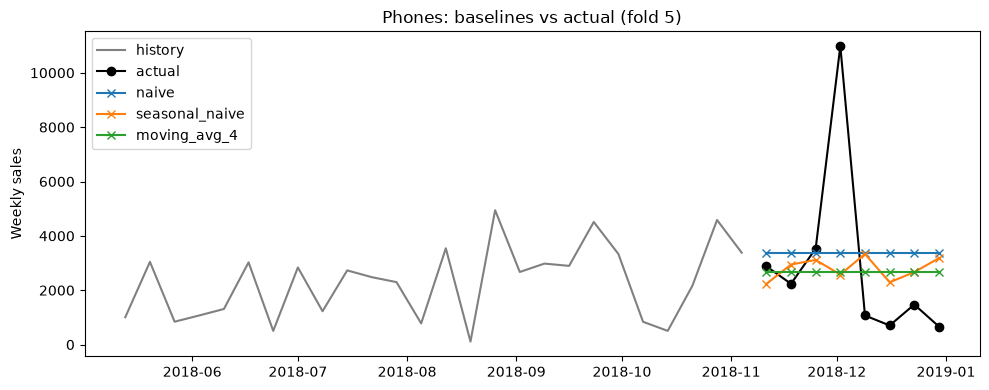

In [18]:
import matplotlib.pyplot as plt  # matplotlib draws the chart

category = "Phones"  # the sub-category we want to inspect
fold_to_plot = 5  # the last fold, which covers the Q4 peak

splits = list(walk_forward_splits(len(weekly), 5, horizon))  # collect all 5 folds' train/test positions into a list
train_idx, test_idx = splits[fold_to_plot - 1]  # pick the chosen fold (lists start at 0, so subtract 1)

train = weekly[category].iloc[train_idx].values  # the history the baselines are allowed to see
actual = weekly[category].iloc[test_idx]  # the real sales in the 8 test weeks, with their dates
history = weekly[category].iloc[train_idx[-26:]]  # only the last 26 training weeks, so the chart stays readable

plt.figure(figsize=(10, 4))  # create a wide, short figure
plt.plot(history.index, history.values, color="gray", label="history")  # draw the recent past in gray
plt.plot(actual.index, actual.values, color="black", marker="o", label="actual")  # draw the real test-week sales in black with dots

for name, model in models.items():  # loop over the three baselines from Step 6
    plt.plot(actual.index, model(train, horizon), marker="x", label=name)  # draw each baseline's 8-week forecast over the same dates

plt.title(f"{category}: baselines vs actual (fold {fold_to_plot})")  # chart title showing the category and fold
plt.ylabel("Weekly sales")  # label the vertical axis
plt.legend()  # show which line is which
plt.tight_layout()  # stop labels from being cut off
plt.show()  # display the chart